In [10]:
%pip install pvlib scikit-learn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/19.4 MB ? eta -:--:--
   ---------- ----------------------------- 5.0/19.4 MB 31.9 MB/s eta 0:00:01
   -------------------------- ------------- 12.8/19.4 MB 35.5 MB/s eta 0:00:01
   ---------------------------------------  19.1/19.4 MB 35.8 MB/s eta 0:00:01
   ---------------------------------------- 19.4/19.4 MB 28.9 MB/s eta 0:00:00


In [1]:
import pvlib
print(pvlib.__version__)

0.16.1


#  Montpellier’s WEATHER DATA, A Typical Meteorological Year (TMY): 8,760 hourly values that represent a normal year.
latitude 43.611, longitude 3.877

In [3]:
weather,meta = pvlib.iotools.get_pvgis_tmy(latitude=43.611, longitude=3.877, map_variables=True)
weather.head()

,temp_air,relative_humidity,ghi,dni,dhi,IR(h),wind_speed,wind_direction,pressure
time(UTC),,,,,,,,,
1990-01-01 00:00:00+00:00,13.23,78.47,0.0,0.0,0.0,330.12,4.84,286.0,101500.0
1990-01-01 01:00:00+00:00,13.13,79.13,0.0,0.0,0.0,329.50,4.73,288.0,101480.0
1990-01-01 02:00:00+00:00,13.03,79.80,0.0,0.0,0.0,328.87,4.61,290.0,101500.0
1990-01-01 03:00:00+00:00,12.93,80.46,0.0,0.0,0.0,328.24,4.50,289.0,101490.0
1990-01-01 04:00:00+00:00,12.83,81.13,0.0,0.0,0.0,327.62,4.39,288.0,101480.0


## 1. Solar resource — Montpellier

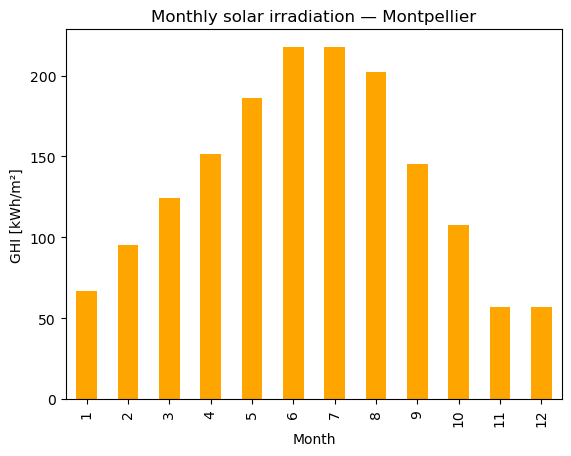

In [4]:
import matplotlib.pyplot as plt

monthly_ghi = weather["ghi"].groupby(weather.index.month).sum() / 1000

monthly_ghi.plot(kind="bar", color="orange")
plt.xlabel("Month")
plt.ylabel("GHI [kWh/m²]")
plt.title("Monthly solar irradiation — Montpellier")
plt.show()

# : Annual total GHI

In [5]:
annual_ghi = monthly_ghi.sum()
print(f"Annual GHI in Montpellier: {annual_ghi:.0f} kWh/m²")

Annual GHI in Montpellier: 1628 kWh/m²
